# Paso 3 · Meta-modelo y evaluación final

**Proyecto de grado — Maestría en Inteligencia Artificial (MAIA), Universidad de los Andes · Grupo 3**

Los pasos 1 y 2 dejaron dos modelos que ven la noche de forma distinta:
- **A (XGBoost):** 911 rasgos calculados a partir de la señal;
- **B (red):** la señal cruda.

Los dos se equivocan, pero no siempre en las mismas épocas. El **meta-modelo** recibe sus probabilidades y aprende a quién creerle en cada caso. Como A y B, es **uno solo para las 12 combinaciones de canales**.

| Sección | Contenido |
|---|---|
| 1 | Configuración y entradas |
| 2 | Alineación de A y B |
| 3 | ¿Se equivocan en lo mismo? |
| 4 | Entradas del meta-modelo |
| 5 | Entrenamiento del meta-modelo |
| 6 | Validación cruzada por combinación |
| 7 | Test: las 12 combinaciones |
| 8 | Test con canales al azar por noche |
| 9 | Confianza: cuándo pedir revisión |
| 10 | Matrices de confusión del sistema final |

Corre en CPU en ~20 minutos.

## 1. Configuración y entradas

`entradas/` tiene lo que dejaron los pasos anteriores:
- `paso_1_xgboost.npz`: probabilidades de A, fuera de fold (`oof`) y de test, para las 12 combinaciones;
- `paso_2_deep_model/` (red original, BiLSTM de 20 épocas) o `paso_2_transformer/` (variante con Transformer entre 80 épocas): un archivo por entrenamiento de B. Los 5 folds dan las predicciones fuera de fold y `final.npz`, las de test. `PASO_2` dice cuál se usa.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
ENTRADAS = RAIZ / "paso_3_meta_model" / "entradas"
PASO_2 = "paso_2_transformer"   # "paso_2_deep_model" para la red original (BiLSTM)
SEED = 42
N_BOOT = 2000

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}
MODALIDADES = ("fpz", "pz", "eog", "emg")
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
K = len(ESTADIOS)


def mascara(cfg):
    return [m in CONFIGS[cfg] for m in MODALIDADES]


def load_a():
    """combinación -> 'oof'/'test' -> noche -> (y, probabilidades)"""
    z = np.load(ENTRADAS / "paso_1_xgboost.npz")
    out = {}
    for k in z.files:
        cfg, key, n, kind = k.split("__")
        if kind == "y":
            out.setdefault(cfg, {}).setdefault(key, {})[n] = (z[k], z[f"{cfg}__{key}__{n}__pred"])
    return out


A = load_a()
print("A:", {key: len(A["fpz"][key]) for key in ("oof", "test")}, "noches")

A: {'oof': 121, 'test': 32} noches


## 2. Alineación de A y B

Las dos predicciones vienen por noche, pero no cubren exactamente las mismas épocas:
- A predice toda la ventana de sueño, incluidas las 298 épocas sin etiqueta (y = −1);
- B solo predice las épocas con etiqueta.

Para que el meta-modelo pueda mirar las épocas vecinas sin huecos, las predicciones de B se ubican en la ventana de A, y las épocas sin etiqueta toman la probabilidad de la época anterior.

In [2]:
def fill_window(y_window, y_valid, p_valid):
    valid = y_window >= 0
    assert np.array_equal(y_window[valid], y_valid), "las etiquetas de A y B no coinciden"
    idx = np.where(valid, np.arange(len(y_window)), -1)
    idx = np.maximum.accumulate(idx)
    idx[idx < 0] = np.argmax(valid)
    full = np.empty((len(y_window), p_valid.shape[1]), dtype=np.float32)
    full[valid] = p_valid
    full[~valid] = full[idx[~valid]]
    return full


def load_b(cfg, key):
    template = A[cfg][key]
    files = [f"fold_{k}" for k in range(5)] if key == "oof" else ["final"]
    out = {}
    for name in files:
        z = np.load(ENTRADAS / PASO_2 / f"{name}.npz")
        for k in z.files:
            if k.startswith(f"{cfg}__"):
                n = k.split("__")[1]
                yw = template[n][0]
                out[n] = (yw, fill_window(yw, z[f"y__{n}"], z[k]))
    assert sorted(out) == sorted(template), f"{cfg}: A y B no tienen las mismas noches"
    return out


B = {cfg: {key: load_b(cfg, key) for key in ("oof", "test")} for cfg in CONFIGS}
VOT = {cfg: {key: {n: (y, (p + B[cfg][key][n][1]) / 2) for n, (y, p) in A[cfg][key].items()} for key in ("oof", "test")}
       for cfg in CONFIGS}   # votación simple: promedio de A y B
print("listo: A, B y la votación, con 12 combinaciones")

listo: A, B y la votación, con 12 combinaciones


## 3. ¿Se equivocan en lo mismo?

Si A y B fallaran en las mismas épocas, combinarlos no serviría de nada. La regla del proyecto: el segundo modelo vale la pena si comparte **menos del 70 %** de los errores del primero (en la CV).

In [3]:
filas = []
for cfg in CONFIGS:
    a, b = A[cfg]["oof"], B[cfg]["oof"]
    ns = sorted(a)
    y = np.concatenate([a[n][0] for n in ns])
    v = y >= 0
    y = y[v]
    pa = np.concatenate([a[n][1].argmax(1) for n in ns])[v]
    pb = np.concatenate([b[n][1].argmax(1) for n in ns])[v]
    ea, eb = pa != y, pb != y
    filas.append({"combinación": cfg, "error A": ea.mean(), "error B": eb.mean(), "fallan los dos": (ea & eb).mean(),
                  "errores de A que B también comete": (ea & eb).sum() / ea.sum(),
                  "N1: B acierta donde A falla": (ea & ~eb & (y == 1)).sum() / (ea & (y == 1)).sum()})
pd.DataFrame(filas).set_index("combinación").style.format("{:.1%}")

,error A,error B,fallan los dos,errores de A que B también comete,N1: B acierta donde A falla
combinación,,,,,
fpz,18.0%,18.0%,10.8%,59.6%,39.7%
pz,20.2%,19.9%,12.8%,63.2%,34.2%
eeg2,16.4%,16.3%,10.1%,61.6%,36.5%
fpz_eog,16.3%,17.1%,10.0%,61.4%,39.8%
pz_eog,17.4%,17.5%,11.2%,64.0%,36.1%
eeg2_eog,15.2%,15.8%,9.8%,64.3%,35.0%
fpz_emg,17.4%,17.6%,10.5%,60.4%,37.4%
pz_emg,19.6%,19.8%,12.6%,64.3%,32.1%
eeg2_emg,16.1%,16.3%,10.1%,62.9%,34.0%


En la tesis: B comparte el **59–65 %** de los errores de A, así que pasa la regla en las 12 combinaciones. Con solo Fpz-Cz, A falla en el 18 % de las épocas y B en el 19 %, pero los dos a la vez solo en el 10.7 %.

## 4. Entradas del meta-modelo

Para cada época *t* el meta-modelo recibe **54 números**:
- las **log-probabilidades** de A y de B en las épocas t−2, t−1, t, t+1 y t+2: 2 modelos × 5 épocas × 5 clases = 50. En los bordes de la noche, las vecinas que no existen valen log(1/5), o sea "no sé";
- la **máscara** de canales presentes [Fpz-Cz, Pz-Oz, EOG, EMG]: 4. Así puede creerle distinto a cada modelo según la combinación; por ejemplo, con un solo EEG el modelo B ayuda más.

Se arma una fila por época y por combinación: **cada época aparece 12 veces**, con lo que dijeron A y B con esa combinación.

In [4]:
EPS = 1e-6
CONTEXT = (-2, -1, 0, 1, 2)


def context_features(level1, models=("xgb", "b"), offsets=CONTEXT):
    nights = sorted(set.intersection(*(set(level1[m]) for m in models)))
    frames = []
    for n in nights:
        y = level1[models[0]][n][0]
        cols = {}
        for m in models:
            lp = np.log(np.clip(level1[m][n][1], EPS, 1))
            for o in offsets:
                shifted = np.full_like(lp, np.log(1 / K))
                if o == 0:
                    shifted = lp
                elif o > 0:
                    shifted[:-o] = lp[o:]
                else:
                    shifted[-o:] = lp[:o]
                for k in range(K):
                    cols[f"{m}_k{k}_o{o:+d}"] = shifted[:, k]
        df = pd.DataFrame(cols)
        df.insert(0, "y", y)
        df.insert(0, "night", n)
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def build_inputs(key):
    frames = []
    for cfg in CONFIGS:
        d = context_features({"xgb": A[cfg][key], "b": B[cfg][key]})
        feat = [c for c in d.columns if c not in ("night", "y")]
        d[feat] = d[feat].astype(np.float32)
        for m, on in zip(MODALIDADES, mascara(cfg)):
            d[f"mask_{m}"] = np.float32(on)
        d.insert(0, "config", cfg)
        frames.append(d)
    return pd.concat(frames, ignore_index=True)


t0 = time.time()
oof_in, test_in = build_inputs("oof"), build_inputs("test")
feat = [c for c in oof_in.columns if c not in ("config", "night", "y")]
print(f"CV: {len(oof_in):,} filas · test: {len(test_in):,} filas · {len(feat)} entradas ({time.time() - t0:.0f} s)")

CV: 1,889,520 filas · test: 459,684 filas · 54 entradas (2 s)


## 5. Entrenamiento del meta-modelo

Adentro hay dos modelos y se promedian sus probabilidades:
- **Regresión logística** (con estandarización, C = 1): aprende reglas lineales, como "si B dice N1 con fuerza y A duda, sube N1".
- **XGBoost pequeño** (profundidad 4, tasa 0.05, hasta 1000 rondas con early stopping de 50 sobre la validación del fold): aprende combinaciones no lineales.

Los dos usan pesos por clase balanceado^0.44.

**Clave para que sea honesto:** se entrena solo con predicciones **fuera de fold**, de personas que A y B nunca vieron. Si se entrenara con predicciones sobre datos de entrenamiento, aprendería a creerles de más.

La CV del meta-modelo usa los mismos 5 folds; el modelo final se entrena con el split `final` y predice el test. Tarda ~13 min.

In [5]:
ALPHA = 0.44
XGB_PARAMS = dict(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss", learning_rate=0.05,
                  max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=10, n_jobs=-1)


def class_weights(y, alpha=ALPHA):
    return compute_sample_weight("balanced", y) ** alpha


class MetaModel:
    """Regresión logística + XGBoost, promediados."""

    def fit(self, X, y, X_val, y_val):
        lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000, random_state=SEED))
        Xt, yt = pd.concat([X, X_val]), np.concatenate([y, y_val])   # la LR no necesita validación: usa todo
        lr.fit(Xt, yt, logisticregression__sample_weight=class_weights(yt))
        m = xgb.XGBClassifier(**XGB_PARAMS, n_estimators=1000, early_stopping_rounds=50, random_state=SEED)
        m.fit(X, y, sample_weight=class_weights(y), eval_set=[(X_val, y_val)],
              sample_weight_eval_set=[class_weights(y_val)], verbose=False)
        self.models = {"lr": lr, "xgb": m}
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models.values()], axis=0)


subj = oof_in.night.str[3:5].astype(int)
lab = oof_in.y.values >= 0


def fit_meta(train_subj, val_subj):
    tr = lab & subj.isin(train_subj).values
    va = lab & subj.isin(val_subj).values
    return MetaModel().fit(oof_in.loc[tr, feat], oof_in.y.values[tr], oof_in.loc[va, feat], oof_in.y.values[va])


def per_config(df, proba):
    out = {}
    for (cfg, n), i in df.groupby(["config", "night"]).indices.items():
        out.setdefault(cfg, {})[n] = (df.y.values[i], proba[i])
    return out


t0 = time.time()
p_oof = np.zeros((len(oof_in), K), dtype=np.float32)
for f in particion["folds"]:
    m = fit_meta(f["train"], f["val"])
    r = subj.isin(f["test"]).values
    p_oof[r] = m.predict_proba(oof_in.loc[r, feat])
    print(f"fold {f['fold'] + 1} ({time.time() - t0:.0f} s)")
meta_final = fit_meta(particion["final"]["train"], particion["final"]["val"])
p_test = meta_final.predict_proba(test_in[feat]).astype(np.float32)
STACK_OOF, STACK_TEST = per_config(oof_in, p_oof), per_config(test_in, p_test)
STACK = {cfg: {"oof": STACK_OOF[cfg], "test": STACK_TEST[cfg]} for cfg in CONFIGS}
print(f"modelo final listo ({time.time() - t0:.0f} s)")

fold 1 (122 s)
fold 2 (219 s)
fold 3 (314 s)
fold 4 (430 s)
fold 5 (525 s)
modelo final listo (676 s)


## 6. Validación cruzada por combinación (62 sujetos)

La **votación** es el promedio simple de A y B, sin aprender nada. Sirve de referencia para ver si el meta-modelo aporta algo más que juntar los dos modelos.

In [6]:
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(K), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(K))}


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y[y >= 0], p[y >= 0])


MODELOS = {"XGBoost (A)": A, "Red (B)": B, "Votación": VOT, "Stacking": STACK}
TESIS_CV = {"fpz": 0.800, "pz": 0.756, "fpz_eog": 0.811, "eeg2_eog_emg": 0.817}
tabla_cv = pd.DataFrame({name: {cfg: metrics_of(P[cfg]["oof"])["mf1"] for cfg in CONFIGS} for name, P in MODELOS.items()})
tabla_cv["tesis (stacking)"] = pd.Series(TESIS_CV)
tabla_cv.style.format(precision=3, na_rep="")

,XGBoost (A),Red (B),Votación,Stacking,tesis (stacking)
fpz,0.768,0.766,0.794,0.802,0.800
pz,0.728,0.737,0.755,0.763,0.756
eeg2,0.783,0.783,0.806,0.812,
fpz_eog,0.788,0.780,0.806,0.811,0.811
pz_eog,0.766,0.770,0.786,0.790,
eeg2_eog,0.798,0.790,0.813,0.819,
fpz_emg,0.776,0.772,0.799,0.804,
pz_emg,0.737,0.740,0.758,0.767,
eeg2_emg,0.788,0.784,0.808,0.814,
fpz_eog_emg,0.791,0.781,0.806,0.812,


## 7. Test: las 12 combinaciones

Se usan los **16 sujetos de test, una sola vez**: todas las decisiones anteriores se tomaron con la CV.

**Intervalos de confianza por bootstrap agrupado por sujeto.** Las épocas de una persona no son independientes, así que se remuestrean **personas** con reemplazo, 2000 veces (semilla 42), y se recalculan las métricas. El 2.5 % y el 97.5 % de los 2000 valores dan el intervalo. Todos los modelos usan las mismas remuestras, así que sus **diferencias son pareadas**: si el IC de la diferencia no cruza 0, es significativa.

In [7]:
METRIC_NAMES = ["acc", "mf1", "kappa"] + [f"f1_{s}" for s in ESTADIOS]


def metrics_from_confusion(cm):
    cm = np.asarray(cm, dtype=np.float64)
    total = cm.sum()
    tp = np.diag(cm)
    precision = np.divide(tp, cm.sum(0), out=np.zeros_like(tp), where=cm.sum(0) > 0)
    recall = np.divide(tp, cm.sum(1), out=np.zeros_like(tp), where=cm.sum(1) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp), where=(precision + recall) > 0)
    po = tp.sum() / total
    pe = (cm.sum(0) * cm.sum(1)).sum() / total**2
    return {"acc": po, "mf1": f1.mean(), "kappa": (po - pe) / (1 - pe), **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)}}


def subject_confusions(preds):
    """noche -> (y, etiquetas)  ->  sujeto -> matriz de confusión"""
    out = {}
    for n, (yt, yp) in preds.items():
        v = yt >= 0
        cm = np.zeros((K, K), dtype=np.int64)
        np.add.at(cm, (yt[v], yp[v]), 1)
        out[int(n[3:5])] = out.get(int(n[3:5]), 0) + cm
    return out


def bootstrap_by_subject(models, n_boot=N_BOOT, seed=SEED):
    cms = {name: subject_confusions(p) for name, p in models.items()}
    subjects = sorted(set.intersection(*(set(c) for c in cms.values())))
    stack = {name: np.stack([c[s] for s in subjects]) for name, c in cms.items()}
    rng = np.random.default_rng(seed)
    rows = []
    for b in range(n_boot):
        idx = rng.integers(0, len(subjects), len(subjects))
        for name, st in stack.items():
            rows.append({"rep": b, "modelo": name, **metrics_from_confusion(st[idx].sum(0))})
    df = pd.DataFrame(rows)
    df.attrs["point"] = {name: metrics_from_confusion(st.sum(0)) for name, st in stack.items()}
    return df


def to_labels(preds):
    return {n: (y, p.argmax(1)) for n, (y, p) in preds.items()}


t0 = time.time()
boot = bootstrap_by_subject({f"{name} | {cfg}": to_labels(P[cfg]["test"]) for cfg in CONFIGS for name, P in MODELOS.items()})
point = boot.attrs["point"]
ic = boot.groupby("modelo")[["mf1", "kappa"]].quantile([0.025, 0.975]).unstack()

filas = []
for cfg in CONFIGS:
    s = f"Stacking | {cfg}"
    filas.append({"combinación": cfg, **{name: point[f"{name} | {cfg}"]["mf1"] for name in MODELOS},
                  "IC 95 % stacking": f"[{ic.loc[s, ('mf1', 0.025)]:.3f}, {ic.loc[s, ('mf1', 0.975)]:.3f}]",
                  "κ stacking": point[s]["kappa"], "F1 N1 stacking": point[s]["f1_N1"]})
print(f"bootstrap: {N_BOOT} remuestras ({time.time() - t0:.0f} s)")
print("tesis (stacking, test): fpz 0.769 [0.733, 0.800] · pz 0.732 · fpz_eog 0.780 · 4 canales 0.780 [0.750, 0.807]")
pd.DataFrame(filas).set_index("combinación").style.format(precision=3)

bootstrap: 2000 remuestras (3 s)
tesis (stacking, test): fpz 0.769 [0.733, 0.800] · pz 0.732 · fpz_eog 0.780 · 4 canales 0.780 [0.750, 0.807]


,XGBoost (A),Red (B),Votación,Stacking,IC 95 % stacking,κ stacking,F1 N1 stacking
combinación,,,,,,,
fpz,0.726,0.749,0.767,0.773,"[0.738, 0.802]",0.751,0.517
pz,0.704,0.710,0.735,0.739,"[0.686, 0.774]",0.706,0.496
eeg2,0.747,0.764,0.780,0.782,"[0.755, 0.806]",0.759,0.526
fpz_eog,0.754,0.758,0.777,0.782,"[0.749, 0.811]",0.755,0.535
pz_eog,0.727,0.737,0.750,0.753,"[0.699, 0.793]",0.717,0.505
eeg2_eog,0.762,0.768,0.783,0.787,"[0.757, 0.812]",0.760,0.535
fpz_emg,0.738,0.752,0.769,0.773,"[0.736, 0.804]",0.747,0.524
pz_emg,0.716,0.713,0.735,0.740,"[0.687, 0.778]",0.704,0.502
eeg2_emg,0.755,0.764,0.781,0.781,"[0.752, 0.805]",0.756,0.529


In [8]:
filas = []
for cfg in CONFIGS:
    wa = boot[boot.modelo == f"Stacking | {cfg}"].set_index("rep")
    for otro in ("XGBoost (A)", "Red (B)", "Votación"):
        wb = boot[boot.modelo == f"{otro} | {cfg}"].set_index("rep")
        d = wa.mf1 - wb.mf1
        filas.append({"combinación": cfg, "contra": otro,
                      "ΔMF1": point[f"Stacking | {cfg}"]["mf1"] - point[f"{otro} | {cfg}"]["mf1"],
                      "IC inf": d.quantile(0.025), "IC sup": d.quantile(0.975)})
dif = pd.DataFrame(filas)
dif["significativa"] = (dif["IC inf"] > 0) | (dif["IC sup"] < 0)
dif.groupby("contra").agg(min=("ΔMF1", "min"), max=("ΔMF1", "max"), significativas=("significativa", "sum")).round(3)

,min,max,significativas
contra,,,
Red (B),0.016,0.029,10
Votación,-0.000,0.007,0
XGBoost (A),0.021,0.047,12


En la tesis, el stacking supera de forma **significativa a A y a B en las 12 combinaciones**, pero **no a la votación simple**. La ganancia viene de combinar dos formas distintas de ver la noche, no de lo sofisticado del meta-modelo.

## 8. Test con canales al azar por noche

En la práctica, cada paciente llega con una combinación distinta de canales. En cada una de las 2000 remuestras:
1. se eligen 16 sujetos con reemplazo;
2. a **cada noche** se le sortea una de las 12 combinaciones, con probabilidad 1/12;
3. se calcula la métrica de esa mezcla.

Los cuatro modelos comparten sujetos y combinaciones, así que las diferencias son pareadas. La cifra central es el valor esperado: todas las noches con las 12 combinaciones, con el mismo peso.

In [9]:
def confusion(y, p):
    v = y >= 0
    return np.bincount(y[v] * K + p.argmax(1)[v], minlength=K * K).reshape(K, K)


def metrics_quick(cm):
    n, tp = cm.sum(), np.diag(cm)
    rows, cols = cm.sum(1), cm.sum(0)
    f1 = np.divide(2 * tp, rows + cols, out=np.zeros(K), where=(rows + cols) > 0)
    pe = (rows * cols).sum() / n**2
    return {"acc": tp.sum() / n, "mf1": f1.mean(), "kappa": (tp.sum() / n - pe) / (1 - pe), "f1_N1": f1[1]}


cfgs = list(CONFIGS)
nights_test = sorted(A["fpz"]["test"])
CM = {name: np.stack([np.stack([confusion(*P[c]["test"][n]) for c in cfgs]) for n in nights_test]) for name, P in MODELOS.items()}
subjects = sorted({int(n[3:5]) for n in nights_test})
by_subject = {s: [i for i, n in enumerate(nights_test) if int(n[3:5]) == s] for s in subjects}
rng = np.random.default_rng(SEED)
boot_mix = {name: [] for name in MODELOS}
for _ in range(N_BOOT):
    idx = np.concatenate([by_subject[s] for s in rng.choice(subjects, size=len(subjects), replace=True)])
    pick = rng.integers(0, len(cfgs), size=len(idx))
    for name in MODELOS:
        boot_mix[name].append(metrics_quick(CM[name][idx, pick].sum(0)))

filas = []
for name in MODELOS:
    b = pd.DataFrame(boot_mix[name])
    pt = metrics_quick(CM[name].sum((0, 1)))
    filas.append({"modelo": name, "MF1": pt["mf1"], "IC 95 %": f"[{b.mf1.quantile(0.025):.3f}, {b.mf1.quantile(0.975):.3f}]",
                  "κ": pt["kappa"], "F1 N1": pt["f1_N1"]})
st_mix = pd.DataFrame(boot_mix["Stacking"]).mf1
for name in ("XGBoost (A)", "Red (B)", "Votación"):
    d = st_mix - pd.DataFrame(boot_mix[name]).mf1
    print(f"Stacking − {name}: {d.mean():+.3f} [{d.quantile(0.025):+.3f}, {d.quantile(0.975):+.3f}]")
print("tesis: stacking 0.764 [0.725, 0.797]")
pd.DataFrame(filas).set_index("modelo").style.format(precision=3)

Stacking − XGBoost (A): +0.029 [+0.014, +0.048]
Stacking − Red (B): +0.022 [+0.006, +0.038]
Stacking − Votación: +0.004 [-0.004, +0.012]
tesis: stacking 0.764 [0.725, 0.797]


,MF1,IC 95 %,κ,F1 N1
modelo,,,,
XGBoost (A),0.740,"[0.696, 0.777]",0.713,0.452
Red (B),0.748,"[0.707, 0.779]",0.717,0.509
Votación,0.766,"[0.725, 0.797]",0.741,0.514
Stacking,0.769,"[0.731, 0.800]",0.741,0.521


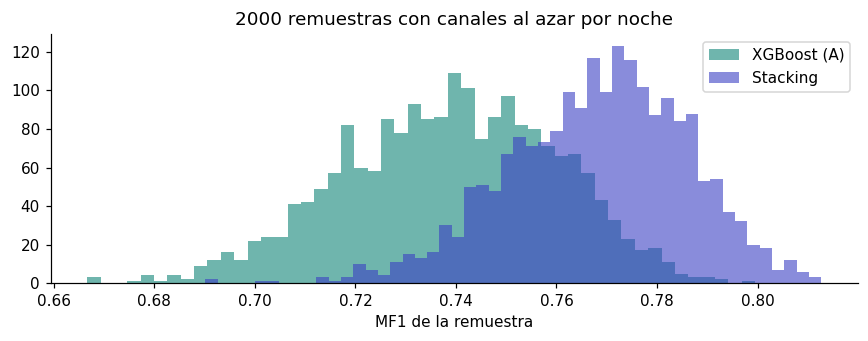

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, color in [("XGBoost (A)", "#0f8577"), ("Stacking", "#3b3fc4")]:
    ax.hist([r["mf1"] for r in boot_mix[name]], bins=50, alpha=0.6, color=color, label=name)
ax.set_xlabel("MF1 de la remuestra")
ax.set_title("2000 remuestras con canales al azar por noche")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Confianza: cuándo pedir revisión

La confianza de una época es la probabilidad de la clase elegida. Si es baja, la época se marca **revisar** y el técnico recibe la 1.ª y la 2.ª opción.

**Reglas, fijadas con la CV antes de mirar el test:**
- **umbral único:** el menor de 0.50, 0.55, …, 0.95 con el que lo que el modelo entrega solo acierta al menos el 90 % en la CV, con las 12 combinaciones juntas;
- **aviso por noche:** si la fracción a revisar supera el percentil 90 de las noches de la CV, se sugiere revisar la noche completa.

In [11]:
GRID = np.round(np.arange(0.50, 0.951, 0.05), 2)


def _f1_macro(cm):
    tp, rows, cols = np.diag(cm), cm.sum(1), cm.sum(0)
    return np.divide(2 * tp, rows + cols, out=np.zeros(K), where=(rows + cols) > 0).mean()


def night_stats(y, p, umbral):
    v = y >= 0
    y, p = y[v], p[v]
    o = np.argsort(-p, 1)
    conf, t1, t2 = p.max(1), o[:, 0], o[:, 1]
    seg, ok, top2 = conf >= umbral, t1 == y, (t1 == y) | (t2 == y)
    cm = np.bincount(y[seg] * K + t1[seg], minlength=K * K).reshape(K, K)
    return {"n": len(y), "seg": seg.sum(), "ok_seg": (ok & seg).sum(), "dud": (~seg).sum(), "ok_dud": (ok & ~seg).sum(),
            "top2_dud": (top2 & ~seg).sum(), "ok": ok.sum(), "combinado": (ok & seg).sum() + (top2 & ~seg).sum(), "cm_seg": cm}


def summarize(stats):
    t = {k: sum(s[k] for s in stats) for k in stats[0]}
    return {"cobertura": t["seg"] / t["n"], "acc_total": t["ok"] / t["n"], "acc_seguras": t["ok_seg"] / t["seg"],
            "mf1_seguras": _f1_macro(t["cm_seg"]), "acc_dudosas": t["ok_dud"] / max(t["dud"], 1),
            "top2_dudosas": t["top2_dud"] / max(t["dud"], 1), "acc_combinada": t["combinado"] / t["n"]}


curva = pd.DataFrame([{"umbral": u, **summarize([night_stats(y, p, u) for c in CONFIGS for y, p in STACK_OOF[c].values()])}
                      for u in GRID]).set_index("umbral")
umbral = float(curva.index[curva.acc_seguras >= 0.90][0])
frac_cv = [s["dud"] / s["n"] for c in CONFIGS for s in (night_stats(y, p, umbral) for y, p in STACK_OOF[c].values())]
aviso = float(np.quantile(frac_cv, 0.90))
print(f"umbral elegido con la CV: {umbral} · aviso por noche si se revisa más del {aviso:.1%}   (tesis: 0.65 y 27.4 %)")
curva.round(3)

umbral elegido con la CV: 0.65 · aviso por noche si se revisa más del 27.3%   (tesis: 0.65 y 27.4 %)


,cobertura,acc_total,acc_seguras,mf1_seguras,acc_dudosas,top2_dudosas,acc_combinada
umbral,,,,,,,
0.50,0.957,0.846,0.863,0.816,0.449,0.822,0.861
0.55,0.914,0.846,0.879,0.830,0.488,0.875,0.879
0.60,0.870,0.846,0.895,0.844,0.515,0.894,0.895
0.65,0.826,0.846,0.910,0.857,0.541,0.905,0.909
0.70,0.780,0.846,0.924,0.870,0.568,0.912,0.921
0.75,0.731,0.846,0.937,0.880,0.597,0.919,0.932
0.80,0.675,0.846,0.950,0.889,0.628,0.925,0.942
0.85,0.610,0.846,0.963,0.894,0.661,0.931,0.951
0.90,0.531,0.846,0.976,0.888,0.698,0.938,0.958


**Calibración:** cuando el modelo dice 80 %, ¿acierta el 80 %? Se agrupan las épocas por tramos de confianza y se compara la confianza media con el acierto real. El ECE es la diferencia media ponderada.

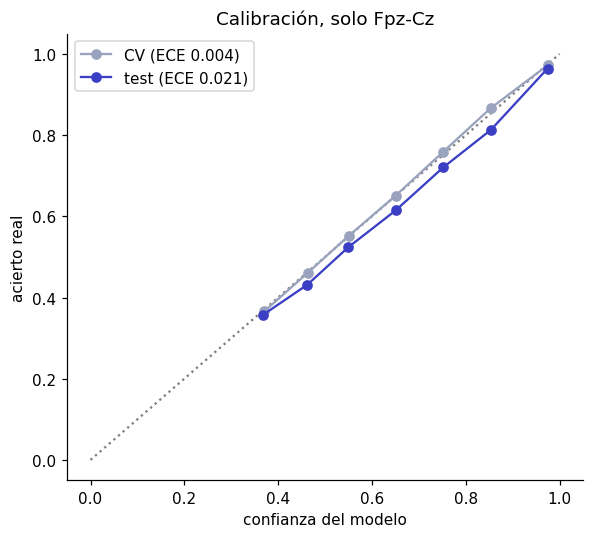

In [12]:
BINS = np.linspace(0, 1, 11)


def calibration(preds):
    y = np.concatenate([v[0] for v in preds.values()])
    p = np.concatenate([v[1] for v in preds.values()])
    v = y >= 0
    y, p = y[v], p[v]
    conf, ok = p.max(1), p.argmax(1) == y
    idx = np.clip(np.digitize(conf, BINS) - 1, 0, len(BINS) - 2)
    t = pd.DataFrame([{"conf": conf[idx == b].mean(), "acierto": ok[idx == b].mean(), "fraccion": (idx == b).mean()}
                      for b in np.unique(idx)])
    return t, (abs(t.acierto - t.conf) * t.fraccion).sum()


fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls=":", color="gray")
for nombre, preds, color in [("CV", STACK_OOF["fpz"], "#9aa3bd"), ("test", STACK_TEST["fpz"], "#3b3fc4")]:
    t, ece = calibration(preds)
    t = t[t.fraccion >= 0.005]
    ax.plot(t.conf, t.acierto, "o-", color=color, label=f"{nombre} (ECE {ece:.3f})")
ax.set_xlabel("confianza del modelo")
ax.set_ylabel("acierto real")
ax.set_title("Calibración, solo Fpz-Cz")
ax.legend()
plt.tight_layout()
plt.show()

**En el test**, con el umbral elegido, con IC por bootstrap por sujeto. La última fila usa la misma combinación al azar por noche de la sección 8:
- **cobertura:** qué parte de la noche entrega el modelo solo;
- **acc_seguras:** acierto en esa parte;
- **top2_dudosas:** en lo marcado "revisar", qué tan seguido la correcta está entre las 2 opciones;
- **acc_total → acc_combinada:** acierto de la noche sin revisión frente a con revisión, si el técnico elige bien entre las 2 opciones.

In [13]:
cols_show = ["cobertura", "acc_seguras", "top2_dudosas", "acc_total", "acc_combinada"]
subj_nights = {s: [n for n in nights_test if int(n[3:5]) == s] for s in subjects}
rng = np.random.default_rng(SEED)
draws = [rng.choice(subjects, size=len(subjects), replace=True) for _ in range(N_BOOT)]
filas, por_noche = [], []
for c in cfgs:
    st = {n: night_stats(*STACK_TEST[c][n], umbral) for n in nights_test}
    pt = summarize(list(st.values()))
    b = pd.DataFrame([summarize([st[n] for s in d for n in subj_nights[s]]) for d in draws])
    filas.append({"combinación": c, **{k: pt[k] for k in cols_show},
                  "IC cobertura": f"[{b.cobertura.quantile(0.025):.3f}, {b.cobertura.quantile(0.975):.3f}]"})
    por_noche += [{"config": c, "noche": n, "fraccion_revisar": s["dud"] / s["n"], "acc": s["ok"] / s["n"]} for n, s in st.items()]

st_all = {(n, c): night_stats(*STACK_TEST[c][n], umbral) for n in nights_test for c in cfgs}
pt = summarize(list(st_all.values()))
rng_mix = np.random.default_rng(SEED)
b = []
for _ in range(N_BOOT):
    idx = [n for s in rng_mix.choice(subjects, size=len(subjects), replace=True) for n in subj_nights[s]]
    pick = rng_mix.integers(0, len(cfgs), size=len(idx))
    b.append(summarize([st_all[(n, cfgs[k])] for n, k in zip(idx, pick)]))
b = pd.DataFrame(b)
filas.append({"combinación": "al azar por noche", **{k: pt[k] for k in cols_show},
              "IC cobertura": f"[{b.cobertura.quantile(0.025):.3f}, {b.cobertura.quantile(0.975):.3f}]"})
print("tesis, al azar por noche: cobertura 0.808 [0.775, 0.836] · acierto 0.876 · 2 opciones 0.848 · 0.80 → 0.87")
pd.DataFrame(filas).set_index("combinación").style.format(precision=3)

tesis, al azar por noche: cobertura 0.808 [0.775, 0.836] · acierto 0.876 · 2 opciones 0.848 · 0.80 → 0.87


,cobertura,acc_seguras,top2_dudosas,acc_total,acc_combinada,IC cobertura
combinación,,,,,,
fpz,0.804,0.887,0.859,0.813,0.882,"[0.769, 0.832]"
pz,0.780,0.849,0.875,0.780,0.855,"[0.750, 0.810]"
eeg2,0.815,0.890,0.863,0.819,0.885,"[0.778, 0.846]"
fpz_eog,0.811,0.889,0.853,0.817,0.882,"[0.782, 0.837]"
pz_eog,0.789,0.869,0.846,0.788,0.864,"[0.760, 0.815]"
eeg2_eog,0.825,0.887,0.875,0.820,0.885,"[0.791, 0.852]"
fpz_emg,0.800,0.887,0.855,0.811,0.881,"[0.765, 0.832]"
pz_emg,0.785,0.848,0.882,0.779,0.855,"[0.752, 0.818]"
eeg2_emg,0.820,0.887,0.866,0.817,0.883,"[0.786, 0.850]"


In [14]:
por_noche = pd.DataFrame(por_noche)
alerta = por_noche.fraccion_revisar > aviso
print(f"noches con aviso: {alerta.sum()} de {len(por_noche)} (noche × combinación) · "
      f"acierto medio con aviso {por_noche.acc[alerta].mean():.3f} frente a {por_noche.acc[~alerta].mean():.3f} sin aviso")

# Así entrega el sistema una noche (test, solo Fpz-Cz): estadio, confianza, 2.ª opción y si hay que revisar
n = nights_test[0]
y, p = STACK_TEST["fpz"][n]
o = np.argsort(-p, 1)
i = np.arange(len(p))
salida = pd.DataFrame({"época": i, "estadio": np.array(ESTADIOS)[o[:, 0]], "confianza": p[i, o[:, 0]].round(3),
                       "2.ª opción": np.array(ESTADIOS)[o[:, 1]], "prob. 2.ª": p[i, o[:, 1]].round(3),
                       "revisar": p[i, o[:, 0]] < umbral, "real": ["?" if v < 0 else ESTADIOS[v] for v in y]})
print(f"{n}: {salida.revisar.mean():.1%} de la noche a revisar")
salida[salida.revisar].head(10)

noches con aviso: 58 de 384 (noche × combinación) · acierto medio con aviso 0.729 frente a 0.818 sin aviso
SC4001: 11.5% de la noche a revisar


,época,estadio,confianza,2.ª opción,prob. 2.ª,revisar,real
59,59,N1,0.604,W,0.390,True,W
64,64,N1,0.568,N2,0.408,True,N2
65,65,N2,0.591,N1,0.394,True,N2
79,79,N2,0.631,N3,0.363,True,N3
99,99,N1,0.574,N2,0.240,True,W
100,100,N3,0.610,N2,0.259,True,N3
114,114,N2,0.450,N1,0.394,True,N2
115,115,N2,0.518,N3,0.386,True,N2
121,121,N2,0.637,N3,0.329,True,N3
124,124,N3,0.641,N2,0.353,True,N3


## 10. Matrices de confusión del sistema final

Test (16 sujetos): solo Fpz-Cz, los 4 canales y la combinación al azar por noche (suma de las 12 combinaciones con el mismo peso). Cada fila es el estadio real y suma 100 %.

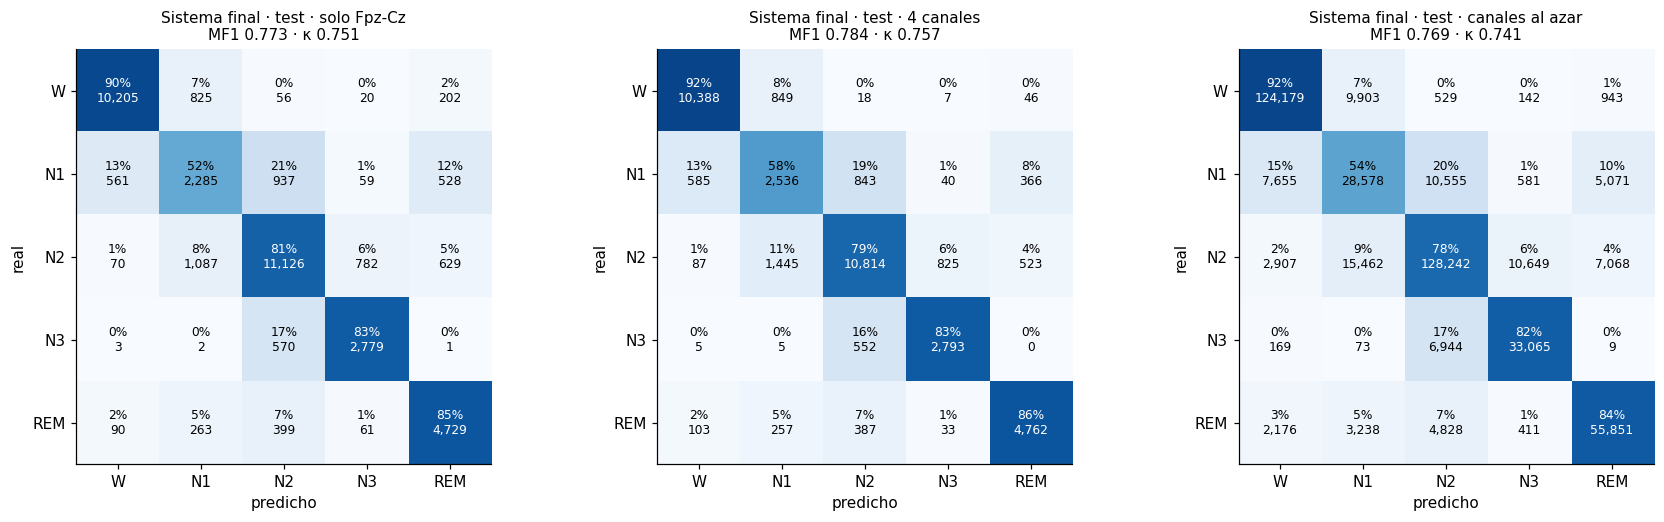

In [15]:
def plot_confusion(cm, title, ax):
    cm = np.asarray(cm)
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(K), ESTADIOS)
    ax.set_yticks(range(K), ESTADIOS)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, c, nombre in zip(axes[:2], ["fpz", "eeg2_eog_emg"], ["solo Fpz-Cz", "4 canales"]):
    m = metrics_of(STACK_TEST[c])
    plot_confusion(m["confusion"], f"Sistema final · test · {nombre}\nMF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}", ax)
cm_mix = CM["Stacking"].sum((0, 1))
mm = metrics_quick(cm_mix)
plot_confusion(cm_mix, f"Sistema final · test · canales al azar\nMF1 {mm['mf1']:.3f} · κ {mm['kappa']:.3f}", axes[2])
plt.tight_layout()
plt.show()

## Resumen

| | Test MF1 [IC 95 %] (tesis) |
|---|---|
| Solo Fpz-Cz | 0.769 [0.733, 0.800] |
| Solo Pz-Oz | 0.732 [0.680, 0.770] |
| Fpz-Cz + EOG | 0.780 [0.745, 0.810] |
| 4 canales | 0.780 [0.750, 0.807] |
| Canales al azar por noche | 0.764 [0.725, 0.797] |

La meta del proyecto con un solo EEG es MF1 ≥ 0.75 y κ ≥ 0.70: Fpz-Cz la cumple, Pz-Oz no. Con el umbral de confianza, el sistema entrega ~81 % de la noche con ~88 % de acierto, y marca el ~19 % restante para revisión con dos opciones.